In [1]:
import os
from pathlib import Path
import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

fig_dir = Path("report/figures")
if not fig_dir.exists():
    for parent in Path.cwd().parents:
        candidate = parent / "report" / "figures"
        if (parent / "pyproject.toml").exists() or (parent / "Taskfile.yml").exists():
            fig_dir = candidate
            break
fig_dir.mkdir(parents=True, exist_ok=True)

wti = pd.read_csv("wti-daily.csv")
wti["Date"] = pd.to_datetime(wti["Date"])
wti = wti.set_index("Date")
wti

,Price
Date,
1986-01-02,25.56
1986-01-03,26.00
1986-01-06,26.53
1986-01-07,25.85
1986-01-08,25.87
...,...
2025-10-21,58.66
2025-10-22,59.30
2025-10-23,62.44


In [2]:
brent = pd.read_csv("brent-daily.csv")
brent["Date"] = pd.to_datetime(brent["Date"])
brent = brent.set_index("Date")
brent

,Price
Date,
1987-05-20,18.63
1987-05-21,18.45
1987-05-22,18.55
1987-05-25,18.60
1987-05-26,18.63
...,...
2025-10-21,61.00
2025-10-22,62.28
2025-10-23,66.32


Q1. Plot the average price trend of oil from 1992-2002

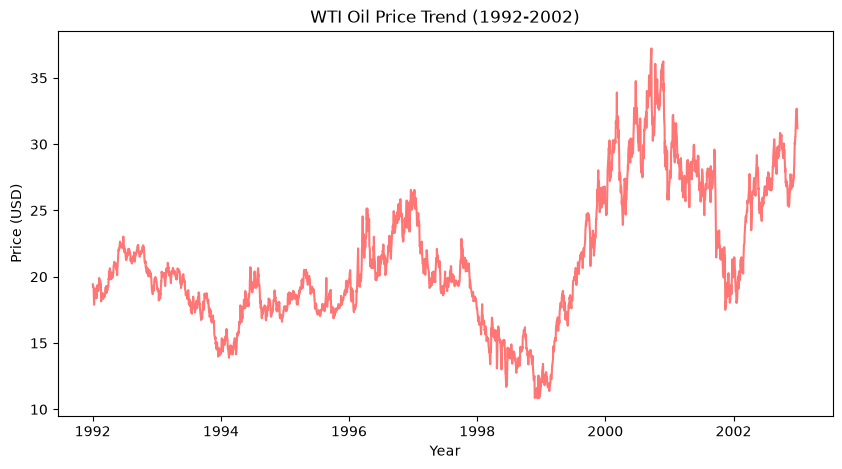

In [3]:
colors = ["#ff7675", "#fab1a0", "#ffeaa7", "#55efc4", "#74b9ff"]

wti_f = wti[(wti.index >= "1992-01-01") & (wti.index <= "2002-12-31")]
plt.figure(figsize=(10, 5))
plt.plot(wti_f, label="WTI", color=colors[0])

plt.title("WTI Oil Price Trend (1992-2002)")
plt.xlabel("Year")
plt.ylabel("Price (USD)")
plt.savefig(fig_dir / "fig_1_1.png", bbox_inches="tight", dpi=300)
plt.show()

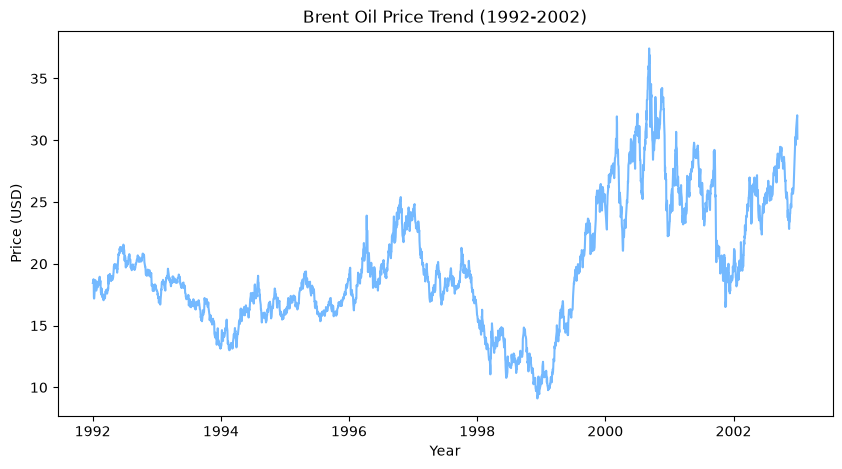

In [4]:
brent_f = brent[(brent.index >= "1992-01-01") & (brent.index <= "2002-12-31")]

plt.figure(figsize=(10, 5))
plt.plot(brent_f, label="Brent", color=colors[-1])
plt.title("Brent Oil Price Trend (1992-2002)")
plt.xlabel("Year")
plt.ylabel("Price (USD)")
plt.savefig(fig_dir / "fig_1_2.png", bbox_inches="tight", dpi=300)
plt.show()

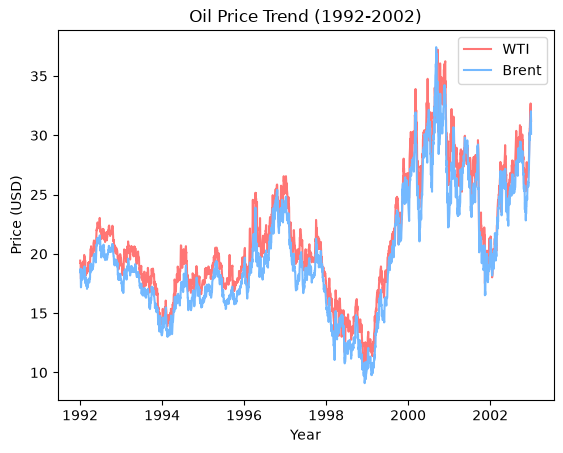

In [5]:
# plot both
plt.plot(wti_f, label="WTI", color=colors[0])
plt.plot(brent_f, label="Brent", color=colors[-1])

plt.title("Oil Price Trend (1992-2002)")
plt.xlabel("Year")
plt.ylabel("Price (USD)")
plt.legend()
plt.show()

In [6]:
# join both datasets on the index (Date)
oil_prices = pd.merge(
  wti_f, brent_f, left_index=True, right_index=True, suffixes=("_WTI", "_Brent")
)
# add diference
oil_prices["Difference"] = np.abs(oil_prices["Price_WTI"] - oil_prices["Price_Brent"])
oil_prices

,Price_WTI,Price_Brent,Difference
Date,,,
1992-01-02,19.43,18.45,0.98
1992-01-03,19.22,18.50,0.72
1992-01-06,19.24,18.75,0.49
1992-01-07,18.72,18.40,0.32
1992-01-08,17.95,17.30,0.65
...,...,...,...
2002-12-23,32.09,30.61,1.48
2002-12-24,32.13,30.93,1.20
2002-12-27,32.68,31.49,1.19


some dates are not in both datasets. for the sake of simplicitly we are discarding those.

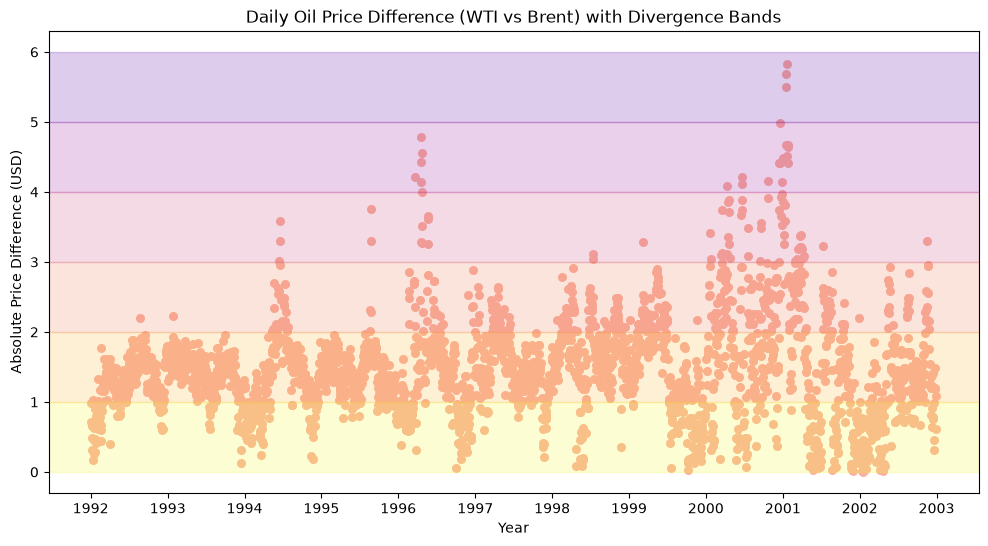

,Price_WTI,Price_Brent,Difference
Date,,,
2001-01-19,32.12,26.29,5.83
2001-01-18,30.42,24.74,5.68
2001-01-17,29.77,24.27,5.50
2000-12-19,29.34,24.36,4.98
1996-04-17,24.67,19.88,4.79
...,...,...,...
1999-10-08,20.81,20.78,0.03
2002-04-23,26.28,26.26,0.02
2002-01-14,18.88,18.89,0.01


In [7]:
plt.figure(figsize=(12, 6))
plt.scatter(
    oil_prices.index, oil_prices["Difference"], label="Difference", color=colors[1], s=30
)

# highlight background with color gradient, with plasma
for i in range(6):
    plt.axhspan(i, i + 1, alpha=0.2, color=plt.cm.plasma(1 - i / 6))

plt.gca().xaxis.set_major_locator(mdates.YearLocator())
plt.gca().xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
plt.title("Daily Oil Price Difference (WTI vs Brent) with Divergence Bands")
plt.xlabel("Year")
plt.ylabel("Absolute Price Difference (USD)")
plt.savefig(fig_dir / "fig_1_4.png", bbox_inches="tight", dpi=300)
plt.show()

oil_prices.sort_values(by="Difference", ascending=False)

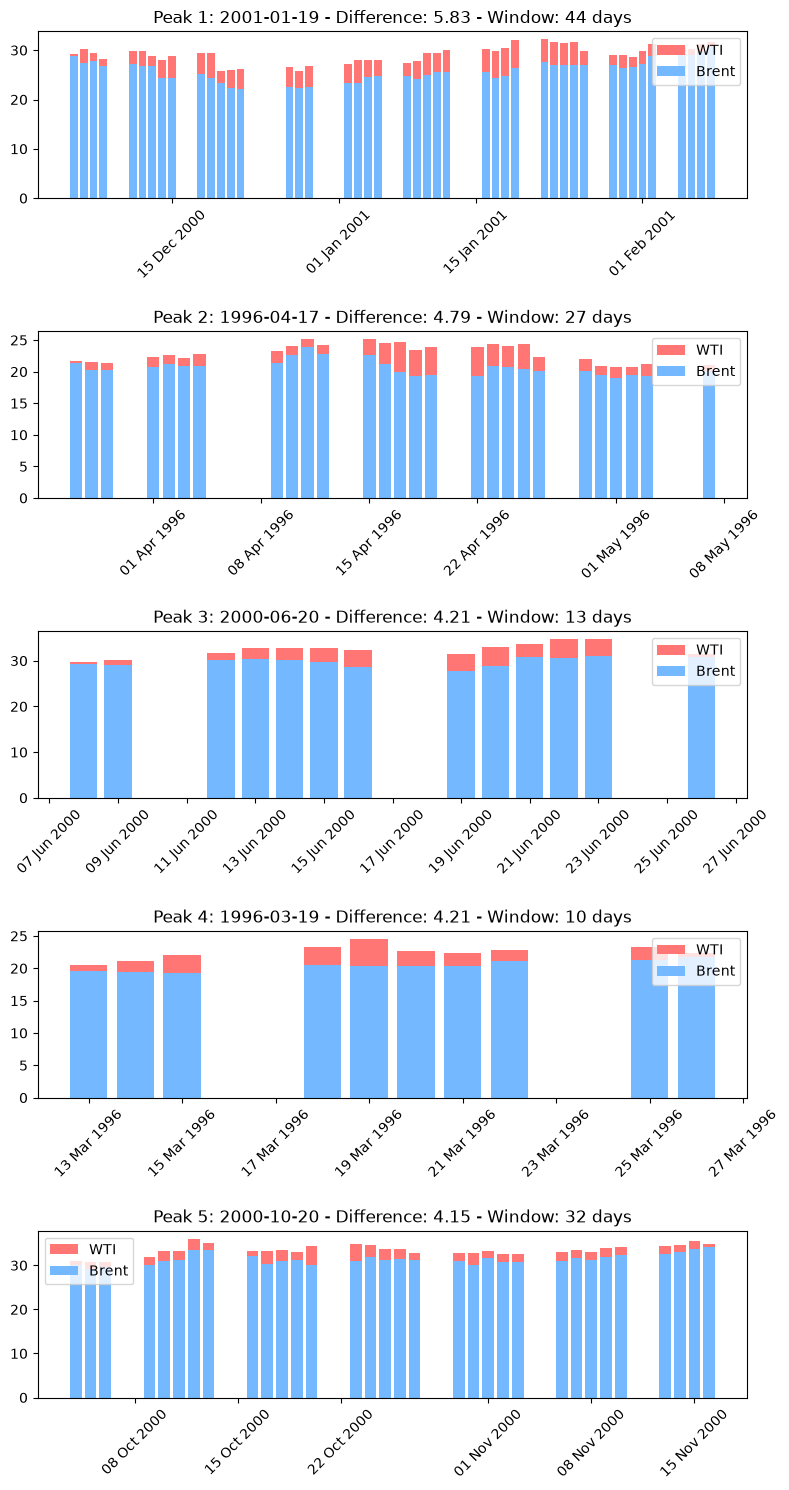

In [8]:
def get_window(peak_date, until_less_than=1):
  peak_pos = oil_prices.index.get_loc(peak_date)
  left = right = peak_pos

  while left > 0 and oil_prices.iloc[left - 1]["Difference"] >= until_less_than:
    left -= 1

  while (
    right < len(oil_prices) - 1
    and oil_prices.iloc[right + 1]["Difference"] >= until_less_than
  ):
    right += 1

  # Include one observation below the threshold on each side
  left = max(0, left - 1)
  right = min(len(oil_prices) - 1, right + 1)

  return oil_prices.iloc[left : right + 1]


def get_highest_all(n):
  checked_peaks = set()
  # sort
  sorted_peaks = oil_prices.sort_values(by="Difference", ascending=False)
  # get the highest peaks
  iterrows = sorted_peaks.iterrows()
  i = 0
  while i != n:
    peak_date, peak = next(iterrows)
    if peak_date in checked_peaks:
      continue
    [checked_peaks.add(date) for date in get_window(peak_date).index]
    i += 1
    if peak["Difference"] < 1:
      break
    yield peak, get_window(peak_date)


fig, axes = plt.subplots(5, 1, figsize=(8, 15))

for i, (peak, window) in enumerate(get_highest_all(5)):
  axes[i].bar(window.index, window["Price_WTI"], label="WTI", color=colors[0])
  axes[i].bar(window.index, window["Price_Brent"], label="Brent", color=colors[-1])

  axes[i].xaxis.set_major_locator(mdates.AutoDateLocator())
  axes[i].xaxis.set_major_formatter(mdates.DateFormatter("%d %b %Y"))
  axes[i].tick_params(axis="x", rotation=45)

  axes[i].set_title(
    f"Peak {i + 1}: {peak.name.date()} - "
    f"Difference: {peak['Difference']:.2f} - "
    f"Window: {len(window)} days"
  )
  axes[i].legend()

plt.tight_layout(h_pad=2.0)
plt.show()

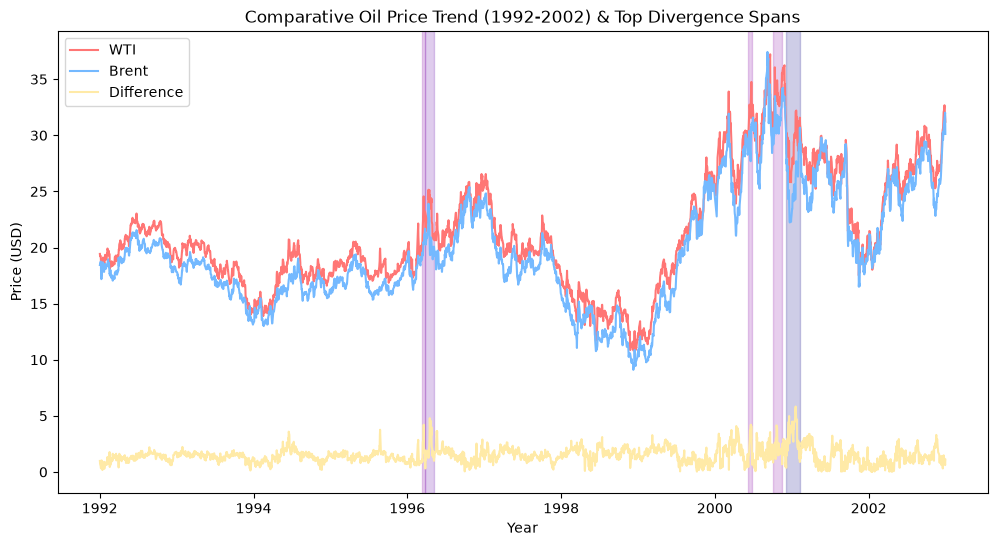

In [9]:
fig, ax = plt.subplots(figsize=(12, 6))
plt.plot(oil_prices.index, oil_prices["Price_WTI"], label="WTI", color=colors[0])
plt.plot(oil_prices.index, oil_prices["Price_Brent"], label="Brent", color=colors[-1])
plt.plot(
    oil_prices.index, oil_prices["Difference"], label="Difference", color=colors[2]
)

# highlight 5 highest peaks
for peak, window in get_highest_all(5):
    ax.axvspan(
        window.index[0],
        window.index[-1],
        alpha=0.2,
        color=plt.cm.plasma(1 - peak["Difference"] / oil_prices["Difference"].max()),
    )

plt.title("Comparative Oil Price Trend (1992-2002) & Top Divergence Spans")
plt.xlabel("Year")
plt.ylabel("Price (USD)")
plt.legend()
plt.savefig(fig_dir / "fig_1_3.png", bbox_inches="tight", dpi=300)
plt.show()